# ITELv5 - SECCIÓN 2: EXPLORACIÓN DE DATOS

In [1]:
import os
from pathlib import Path

# Asegurar que el CWD sea la carpeta de notebooks
# (IntelliJ puede configurar un CWD distinto al de Jupyter Lab)
_anchor = Path('ITELv5_01_CONFIGURACION.ipynb')
if not _anchor.exists():
    for _candidate in Path.cwd().rglob('ITELv5_01_CONFIGURACION.ipynb'):
        os.chdir(_candidate.parent)
        break
print(f'📂 CWD: {Path(".").resolve()}')


📂 CWD: C:\Users\USER\Documents\GitHub\ITEL\research\notebooks


In [2]:
# ===============================================================_
# ITELv5 - SECCIÓN 2: EXPLORACIÓN DE DATOS
# ===============================================================_

# Cargar configuración y utilidades globales
%run "./ITELv5_01_CONFIGURACION.ipynb"
print("✅ Configuración ITELv5 cargada")

🔍 Verificando estructura de carpetas...
  ✅ Datos_Brutos: 1680 WAV Healthy  |  2173 WAV Patients
  ✅ Todas las dependencias disponibles.

📁 BASE_DIR : C:\Users\USER\Documents\GitHub\ITEL\research
📂 DATA_DIR : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
🖥️  GPU      : False
Rutas del proyecto ITELv5:
  Datos_Brutos    : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
  Procesados      : C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
  Modelos         : C:\Users\USER\Documents\GitHub\ITEL\assets\models
  Reportes CSV    : C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV
  Reportes Figuras: C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras
  Logs            : C:\Users\USER\Documents\GitHub\ITEL\research\logs

🔍 Healthy  : 308 subrutas de audio
🔍 Patients : 378 subrutas de audio

✅ Configuración ITELv5 lista.
✅ Configuración ITELv5 cargada


In [3]:
# ===============================================================_
# 2.1 - Verificación de estructura de carpetas
# ===============================================================_
from pathlib import Path

def verificar_estructura_directorios():
    print("🔍 Verificando estructura de carpetas ITELv5 (desde Notebook 02)...")
    
    # Estas rutas ya fueron verificadas por 01_CONFIGURACION, 
    # pero esta celda ofrece un desglose de lo que 02 espera.
    
    base = ITELConfig.BASE_DIR
    
    print(f"\n{'✅' if ITELConfig.DATA_DIR.exists() else '❌'} Datos_Brutos: {ITELConfig.DATA_DIR}")
    if ITELConfig.DATA_DIR.exists():
        path_h = ITELConfig.DATA_DIR / 'Healthy'
        path_p = ITELConfig.DATA_DIR / 'Patients'
        print(f"   └── {'✅' if path_h.exists() else '❌'} Healthy")
        print(f"   └── {'✅' if path_p.exists() else '❌'} Patients")

    print(f"\n{'✅' if ITELConfig.REPORTES_DIR.exists() else '❌'} Reportes: {ITELConfig.REPORTES_DIR}")
    if ITELConfig.REPORTES_DIR.exists():
        print(f"   └── {'✅' if ITELConfig.CSV_DIR.exists() else '❌'} CSV")
        print(f"   └── {'✅' if ITELConfig.FIGURAS_DIR.exists() else '❌'} Figuras")
    
    print(f"\n{'✅' if ITELConfig.LOGS_DIR.exists() else '❌'} Logs: {ITELConfig.LOGS_DIR}")
    
    print("\nVerificación completada.")

verificar_estructura_directorios()

🔍 Verificando estructura de carpetas ITELv5 (desde Notebook 02)...

✅ Datos_Brutos: C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
   └── ✅ Healthy
   └── ✅ Patients

✅ Reportes: C:\Users\USER\Documents\GitHub\ITEL\research\reports
   └── ✅ CSV
   └── ✅ Figuras

✅ Logs: C:\Users\USER\Documents\GitHub\ITEL\research\logs

Verificación completada.


In [4]:
# ===============================================================_
# 2.2 - Conteo y listado de archivos
# ===============================================================_
import pandas as pd
from pathlib import Path

def listar_archivos_por_categoria():
    print("📂 Listando archivos de audio en Datos_Brutos/Healthy y Datos_Brutos/Patients...")
    
    # Usa la nueva ruta ITELConfig.DATA_DIR
    categorias = {
        'Healthy': ITELConfig.DATA_DIR / 'Healthy',
        'Patients': ITELConfig.DATA_DIR / 'Patients'
    }

    registros = []

    for categoria, ruta in categorias.items():
        if not ruta.exists():
            print(f"⚠️ Carpeta no encontrada: {ruta}")
            continue

        archivos = list(ruta.rglob('*.wav')) + list(ruta.rglob('*.mp3'))
        print(f"   {categoria}: {len(archivos)} archivos encontrados")

        for archivo in archivos:
            registros.append({
                'categoria': categoria,
                'nombre': archivo.name,
                'ruta': str(archivo),
                'tamaño_kb': round(archivo.stat().st_size / 1024, 2)
            })

    df = pd.DataFrame(registros)
    print(f"\n📊 Total general de archivos: {len(df)}")
    return df

df_audios = listar_archivos_por_categoria()
df_audios.head()

📂 Listando archivos de audio en Datos_Brutos/Healthy y Datos_Brutos/Patients...
   Healthy: 1680 archivos encontrados
   Patients: 2173 archivos encontrados

📊 Total general de archivos: 3853


,categoria,nombre,ruta,tamaño_kb
0,Healthy,6DR1A.WAV,C:\Users\USER\Documents\GitHub\ITEL\research\D...,13.16
1,Healthy,6DR1E.WAV,C:\Users\USER\Documents\GitHub\ITEL\research\D...,11.08
2,Healthy,6DR1I.WAV,C:\Users\USER\Documents\GitHub\ITEL\research\D...,7.68
3,Healthy,6DR1O.WAV,C:\Users\USER\Documents\GitHub\ITEL\research\D...,11.97
4,Healthy,6DR1U.WAV,C:\Users\USER\Documents\GitHub\ITEL\research\D...,10.18


In [5]:
# ===============================================================_
# 2.3 - Análisis de propiedades de audio
# ===============================================================_
import librosa
import numpy as np
import pandas as pd

def analizar_propiedades_por_categoria(df, n=None):
    print("🎧 Analizando propiedades de audio por categoría...")

    if df.empty:
        print("⚠️ No hay archivos para analizar.")
        return pd.DataFrame()

    if n:
        df = df.sample(min(n, len(df)), random_state=42)

    resultados = []

    for _, row in df.iterrows():
        try:
            y, sr = librosa.load(row['ruta'], sr=None)
            duracion = len(y) / sr
            amp_max = np.max(np.abs(y))
            rms = np.sqrt(np.mean(y ** 2))

            resultados.append({
                'categoria': row['categoria'],
                'nombre': row['nombre'],
                'duracion_s': round(duracion, 3),
                'sample_rate': sr,
                'amplitud_max': round(float(amp_max), 5),
                'rms': round(float(rms), 5)
            })

        except Exception as e:
            print(f"⚠️ Error al procesar {row['nombre']}: {e}")

    df_prop = pd.DataFrame(resultados)
    print(f"✅ Archivos analizados: {len(df_prop)}")
    return df_prop

df_propiedades = analizar_propiedades_por_categoria(df_audios)
df_propiedades.head()

🎧 Analizando propiedades de audio por categoría...
✅ Archivos analizados: 3853


,categoria,nombre,duracion_s,sample_rate,amplitud_max,rms
0,Healthy,6DR1A.WAV,0.420,16000,0.90009,0.19434
1,Healthy,6DR1E.WAV,0.353,16000,0.52072,0.17533
2,Healthy,6DR1I.WAV,0.244,16000,0.81830,0.32188
3,Healthy,6DR1O.WAV,0.382,16000,0.55243,0.19284
4,Healthy,6DR1U.WAV,0.324,16000,0.54346,0.20267


📊 Estadísticas descriptivas por categoría:
          duracion_s                                                     \
               count    mean     std    min    25%    50%    75%    max   
categoria                                                                 
Healthy       1680.0  0.5353  0.2611  0.049  0.343  0.456  0.690  1.834   
Patients      2173.0  0.6606  0.4211  0.045  0.409  0.551  0.808  4.587   

          amplitud_max          ...                    rms                  \
                 count    mean  ...     75%    max   count    mean     std   
categoria                       ...                                          
Healthy         1680.0  0.3610  ...  0.4837  1.000  1680.0  0.0865  0.0601   
Patients        2173.0  0.0692  ...  0.0854  0.642  2173.0  0.0164  0.0103   

                                                   
              min     25%     50%     75%     max  
categoria                                          
Healthy    0.0121  0.0437  0.0682 

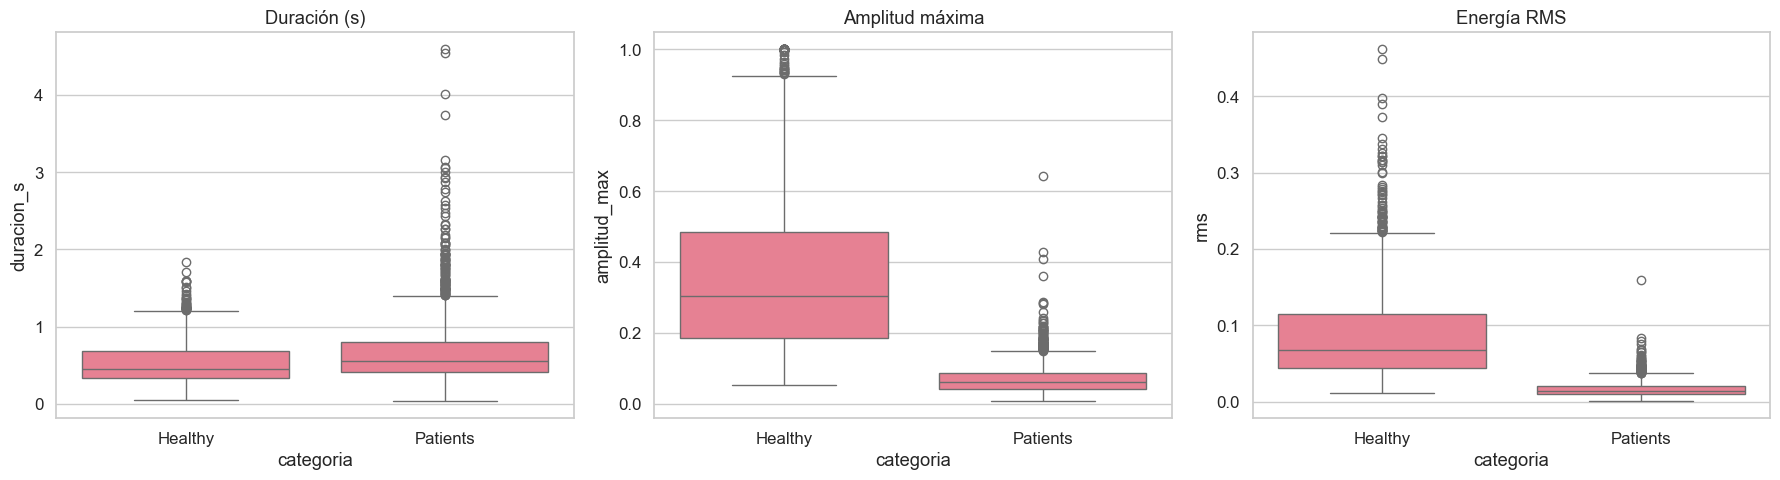

In [6]:
# ===============================================================_
# 2.4 - Estadísticas descriptivas
# ===============================================================_
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def estadisticas_comparativas(df):
    if df.empty:
        print("⚠️ No hay datos para analizar.")
        return None

    print("📊 Estadísticas descriptivas por categoría:")

    resumen = (
        df.groupby('categoria')[["duracion_s", "amplitud_max", "rms"]]
        .describe()
        .round(4)
    )

    print(resumen)

    sns.set(style='whitegrid', palette='husl', font_scale=1.1)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    sns.boxplot(x='categoria', y='duracion_s', data=df, ax=axes[0]).set(title='Duración (s)')
    sns.boxplot(x='categoria', y='amplitud_max', data=df, ax=axes[1]).set(title='Amplitud máxima')
    sns.boxplot(x='categoria', y='rms', data=df, ax=axes[2]).set(title='Energía RMS')

    plt.tight_layout()
    plt.show()

    return resumen

resumen_stats = estadisticas_comparativas(df_propiedades)

🎧 Calculando frecuencia dominante y velocidad de muestreo...
✅ Métricas obtenidas para 3853 archivos.


C:\Users\USER\AppData\Local\Temp\ipykernel_34512\2419356355.py:56: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(ax=axes[1,1], x='categoria', y='frecuencia_dominante_kHz', data=df, inner='quartile', scale='width')


💾 Exportado: C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras\frecuencia_sample_general_v5.png
💾 Exportado: C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras\frecuencia_sample_muestra_v5.png
🔹 Muestra analizada: 4jk4pivo.wav


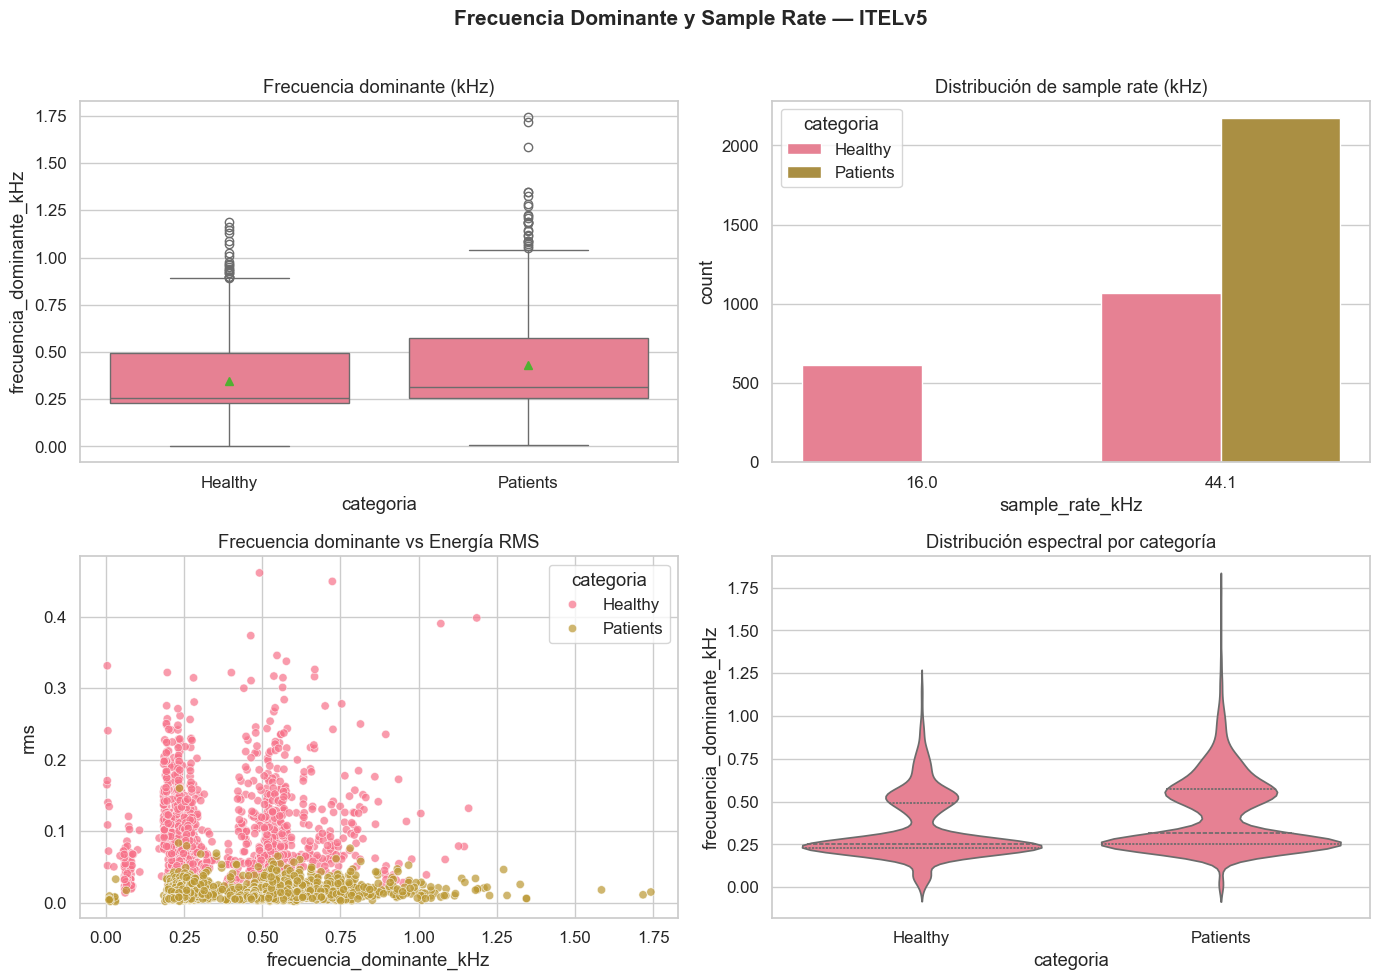

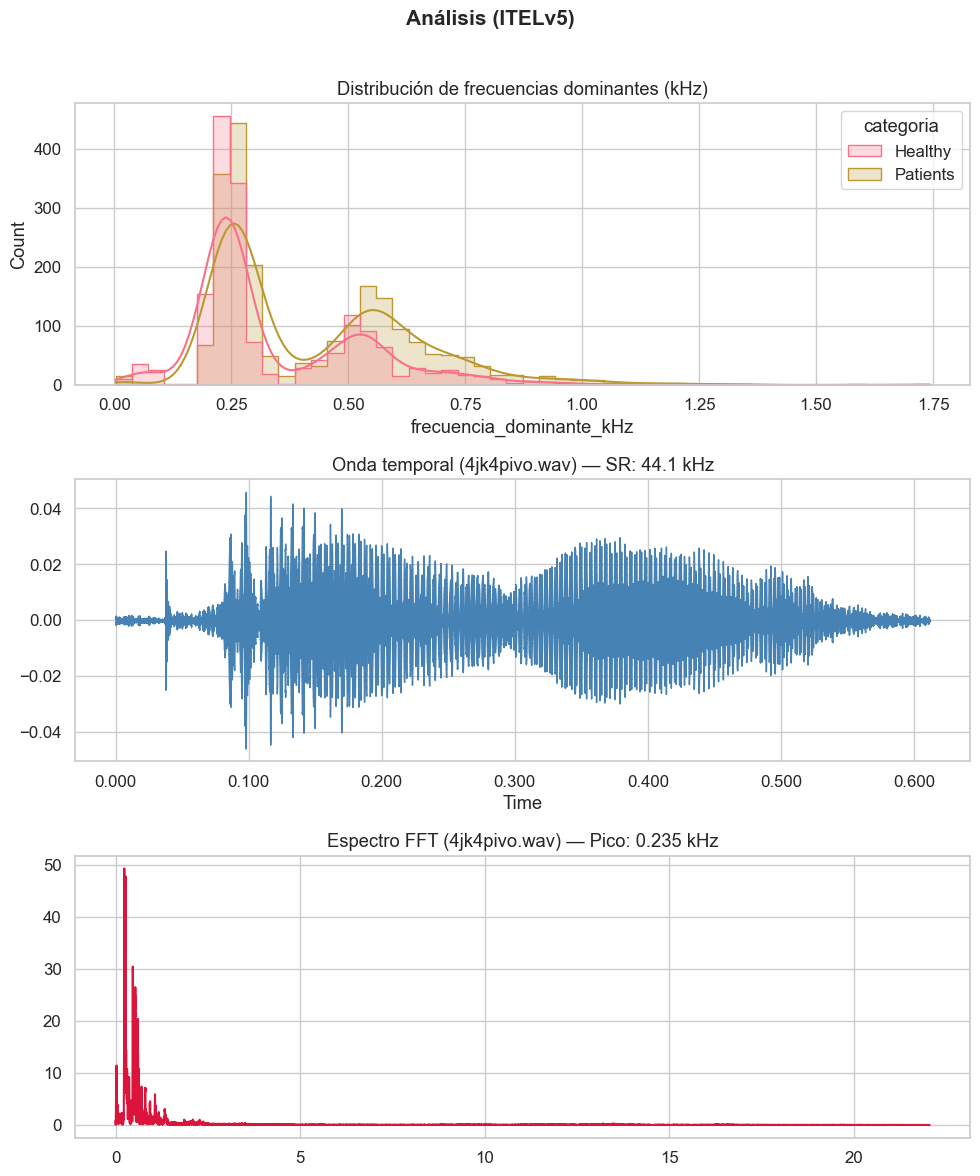

In [7]:
# ===============================================================_
# 2.5 - Frecuencia dominante y velocidad de muestreo
# ===============================================================_
import librosa, librosa.display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random

def detectar_frecuencia_y_sample(df):
    print("🎧 Calculando frecuencia dominante y velocidad de muestreo...")
    if df.empty:
        print("⚠️ No hay archivos para analizar.")
        return pd.DataFrame()
    resultados = []
    for _, row in df.iterrows():
        try:
            y, sr = librosa.load(row['ruta'], sr=None)
            y = y - np.mean(y)
            N = len(y)
            freqs = np.fft.rfftfreq(N, 1/sr)
            magnitudes = np.abs(np.fft.rfft(y))
            magnitudes[0] = 0
            freq_dom = freqs[np.argmax(magnitudes)] / 1000
            resultados.append({
                'categoria': row['categoria'],
                'nombre': row['nombre'],
                'frecuencia_dominante_kHz': round(float(freq_dom), 3),
                'sample_rate_kHz': round(sr / 1000, 2)
            })
        except Exception as e:
            print(f"⚠️ Error al procesar {row['nombre']}: {e}")
    df_result = pd.DataFrame(resultados)
    print(f"✅ Métricas obtenidas para {len(df_result)} archivos.")
    return df_result


df_frecuencia_sample = detectar_frecuencia_y_sample(df_audios)


def graficos_frecuencia_general(df):
    sns.set(style='whitegrid', palette='husl', font_scale=1.1)
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    plt.subplots_adjust(hspace=0.4, wspace=0.3)
    sns.boxplot(ax=axes[0,0], x='categoria', y='frecuencia_dominante_kHz', data=df, showmeans=True)
    axes[0,0].set_title('Frecuencia dominante (kHz)')
    sns.countplot(ax=axes[0,1], x='sample_rate_kHz', hue='categoria', data=df)
    axes[0,1].set_title('Distribución de sample rate (kHz)')
    try:
        df_merge = df_propiedades.merge(df, on=['nombre', 'categoria'])
        sns.scatterplot(ax=axes[1,0], data=df_merge, x='frecuencia_dominante_kHz', y='rms', hue='categoria', alpha=0.7)
        axes[1,0].set_title('Frecuencia dominante vs Energía RMS')
    except Exception as e:
        axes[1,0].text(0.5, 0.5, f'No disponible RMS\n{e}', ha='center', va='center')
    sns.violinplot(ax=axes[1,1], x='categoria', y='frecuencia_dominante_kHz', data=df, inner='quartile', scale='width')
    axes[1,1].set_title('Distribución espectral por categoría')
    plt.suptitle('Frecuencia Dominante y Sample Rate — ITELv5', fontsize=15, fontweight='bold')
    plt.tight_layout(rect=[0,0,1,0.97])
    
    # --- Cambio de Ruta ---
    save_path = ITELConfig.FIGURAS_DIR / 'frecuencia_sample_general_v5.png'
    fig.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f'💾 Exportado: {save_path}')


def graficos_frecuencia_muestra(df_frec, df_audios):
    sns.set(style='whitegrid', palette='husl', font_scale=1.1)
    fig, axes = plt.subplots(3, 1, figsize=(10, 12))
    plt.subplots_adjust(hspace=0.5)
    sns.histplot(ax=axes[0], data=df_frec, x='frecuencia_dominante_kHz', hue='categoria', kde=True, bins=50, element='step', common_norm=False)
    axes[0].set_title('Distribución de frecuencias dominantes (kHz)')
    
    muestra = random.choice(df_audios['nombre'].tolist())
    ruta = df_audios.loc[df_audios['nombre'] == muestra, 'ruta'].values[0]
    
    y, sr = librosa.load(ruta, sr=None)
    y = y - np.mean(y)
    N = len(y)
    freqs = np.fft.rfftfreq(N, 1/sr)
    magnitudes = np.abs(np.fft.rfft(y))
    magnitudes[0] = 0
    freq_dom = freqs[np.argmax(magnitudes)] / 1000
    
    librosa.display.waveshow(y, sr=sr, color='steelblue', ax=axes[1])
    axes[1].set_title(f'Onda temporal ({muestra}) — SR: {sr/1000:.1f} kHz')
    
    axes[2].plot(freqs/1000, magnitudes, color='crimson')
    axes[2].set_title(f'Espectro FFT ({muestra}) — Pico: {freq_dom:.3f} kHz')
    
    plt.suptitle('Análisis (ITELv5)', fontsize=15, fontweight='bold')
    plt.tight_layout(rect=[0,0,1,0.97])
    
    # --- Cambio de Ruta ---
    save_path_muestra = ITELConfig.FIGURAS_DIR / 'frecuencia_sample_muestra_v5.png'
    fig.savefig(save_path_muestra, dpi=300, bbox_inches='tight')
    print(f'💾 Exportado: {save_path_muestra}\n🔹 Muestra analizada: {muestra}')


graficos_frecuencia_general(df_frecuencia_sample)

graficos_frecuencia_muestra(df_frecuencia_sample, df_audios)

In [8]:
# ===============================================================_
# 2.6 - Resumen de exploración
# ===============================================================_

def resumen_exploracion(df_stats, df_propiedades):
    print('\n🧾 RESUMEN DE EXPLORACIÓN DE DATOS')
    print('=' * 50)
    if df_stats is not None and not df_stats.empty:
        print(df_stats)
    print(f'\nArchivos analizados: {len(df_propiedades)}')

resumen_exploracion(resumen_stats, df_propiedades)
print('\n✅ Sección 2 (v5) completada. Listo para Gestión de Contenido (Sección 3).')


🧾 RESUMEN DE EXPLORACIÓN DE DATOS
          duracion_s                                                     \
               count    mean     std    min    25%    50%    75%    max   
categoria                                                                 
Healthy       1680.0  0.5353  0.2611  0.049  0.343  0.456  0.690  1.834   
Patients      2173.0  0.6606  0.4211  0.045  0.409  0.551  0.808  4.587   

          amplitud_max          ...                    rms                  \
                 count    mean  ...     75%    max   count    mean     std   
categoria                       ...                                          
Healthy         1680.0  0.3610  ...  0.4837  1.000  1680.0  0.0865  0.0601   
Patients        2173.0  0.0692  ...  0.0854  0.642  2173.0  0.0164  0.0103   

                                                   
              min     25%     50%     75%     max  
categoria                                          
Healthy    0.0121  0.0437  0.0682  0.1145 

In [9]:
# ===============================================================_
# 2.7 - Exportar resultados clave
# ===============================================================_

# Esta celda usa ITELConfig.CSV_DIR, que ya está actualizado.
csv_dir = ITELConfig.CSV_DIR

df_propiedades_path = csv_dir / 'df_propiedades_v5.csv'
df_propiedades.to_csv(df_propiedades_path, index=False)
print(f'💾 df_propiedades exportado a {df_propiedades_path}')

resumen_stats_path = csv_dir / 'resumen_stats_v5.csv'
resumen_stats.to_csv(resumen_stats_path)
print(f'💾 resumen_stats exportado a {resumen_stats_path}')

💾 df_propiedades exportado a C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\df_propiedades_v5.csv
💾 resumen_stats exportado a C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\resumen_stats_v5.csv
